# American Put Option on KO using PDE

# Author: Jaime Corzo Galdó

The objective is to price an American put option on Coca-Cola (KO) using the explicit finite difference method for the Black-Scholes PDE.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

## 1. Market data and option selection

We first obtain the latest available KO stock price and select a short-dated put option close to at-the-money.

In [2]:
# Download KO market data

ticker = yf.Ticker("KO")

history = ticker.history(period="5d")
S0 = history["Close"].iloc[-1]

print(f"Latest KO close: ${S0:.2f}")
print("Available expirations:")
print(ticker.options[:10])

Latest KO close: $92.71
Available expirations:
('2026-10-30', '2026-11-06', '2026-11-13', '2026-11-20', '2026-11-27', '2026-12-04', '2026-12-18', '2027-01-15', '2027-02-19', '2027-03-19')


We use the November 20, 2026 expiration. This is a relatively short-dated option.

The strike closest to the current stock price is selected so that the put is approximately at-the-money.

In [3]:
expiration = "2026-11-20"

chain = ticker.option_chain(expiration)
puts = chain.puts.copy()

# Select the strike closest to the current stock price
idx = (puts["strike"] - S0).abs().idxmin()
put = puts.loc[idx]

K = put["strike"]
sigma = put["impliedVolatility"]

bid = put["bid"]
ask = put["ask"]
P_MKT = (bid + ask) / 2

print(f"Stock price:        ${S0:.2f}")
print(f"Strike:             ${K:.2f}")
print(f"Bid:                ${bid:.2f}")
print(f"Ask:                ${ask:.2f}")
print(f"Market midpoint:    ${P_MKT:.2f}")
print(f"Implied volatility: {sigma:.2%}")

Stock price:        $92.71
Strike:             $92.50
Bid:                $1.91
Ask:                $2.12
Market midpoint:    $2.02
Implied volatility: 22.14%


In [4]:
put[[
    "contractSymbol",
    "lastTradeDate",
    "strike",
    "lastPrice",
    "bid",
    "ask",
    "impliedVolatility",
    "volume",
    "openInterest"
]]

contractSymbol               KO261120P00092500
lastTradeDate        2026-10-23 19:45:47+00:00
strike                                    92.5
lastPrice                                 1.99
bid                                       1.91
ask                                       2.12
impliedVolatility                     0.221443
volume                                    92.0
openInterest                               913
Name: 25, dtype: object

## 2. Model inputs

The valuation date is October 23, 2026, which is the date of the market data used above. The option expires on November 20, 2026.

For the risk-free rate, we use the 4-week U.S. Treasury bill rate because its maturity is close to the option maturity.

No dividend is expected before the option expires, so the dividend yield over the life of this option is set to zero.

In [ ]:
# Freeze the market snapshot used in the analysis

valuation_date = pd.Timestamp("2026-10-23")
expiration_date = pd.Timestamp("2026-11-20")

S0 = 92.71
K = 92.50
sigma = 0.221443

bid = 1.91
ask = 2.12
P_MKT = (bid + ask) / 2

r = 0.0401 # the 4 weeks risk free rate obtained from the U.S. Treasury yield curve (https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_yield_curve&field_tdr_date_value=2026) on the valuation date.
q = 0.0 # because the dividend yield of KO is 0.0% (https://www.nasdaq.com/market-activity/stocks/ko/dividend-history) on the valuation date.

# Time to expiration in years
T = (expiration_date - valuation_date).days / 365

# Cost of carry
b = r - q

print(f"Time to expiration: {T:.4f} years")
print(f"Market midpoint:    ${P_MKT:.3f}")

Time to expiration: 0.0767 years
Market midpoint:    $2.015


## 3. PDE grid

We solve the PDE in log-price space,

$$
x = \ln\left(\frac{S}{S_0}\right).
$$

Instead of fixing arbitrary minimum and maximum stock prices, the grid is chosen to cover six volatility standard deviations on each side of the current stock price.

This places the boundaries sufficiently far from the current stock price while keeping the grid concentrated on the relevant region.

In [6]:
# Grid parameters

NX = 300
NT = 1000

L = 6

x_min = -L * sigma * np.sqrt(T)
x_max =  L * sigma * np.sqrt(T)

x_grid = np.linspace(x_min, x_max, NX + 1)
dx = (x_max - x_min) / NX

S_grid = S0 * np.exp(x_grid)

dt = T / NT
t_grid = np.linspace(0, T, NT + 1)

print(f"Stock price range: ${S_grid[0]:.2f} to ${S_grid[-1]:.2f}")
print(f"dx = {dx:.6f}")
print(f"dt = {dt:.8f}")

Stock price range: $64.17 to $133.95
dx = 0.002453
dt = 0.00007671


## 4. Finite difference weights and stability

The explicit PDE method uses three neighboring points at the next time step. Their weights are

$$
p_u =
\frac{\sigma^2\Delta t}{2\Delta x^2}
+
\frac{(r-q-\frac{1}{2}\sigma^2)\Delta t}{2\Delta x},
$$

$$
p_m =
1-\frac{\sigma^2\Delta t}{\Delta x^2},
$$

and

$$
p_d =
\frac{\sigma^2\Delta t}{2\Delta x^2}
-
\frac{(r-q-\frac{1}{2}\sigma^2)\Delta t}{2\Delta x}.
$$

For the explicit scheme to be stable, these weights should remain non-negative.

In [7]:
# Explicit finite difference weights

pu = (sigma**2 * dt) / (2 * dx**2) + \
     (b - sigma**2 / 2) * dt / (2 * dx)

pm = 1 - (sigma**2 * dt) / dx**2

pd = (sigma**2 * dt) / (2 * dx**2) - \
     (b - sigma**2 / 2) * dt / (2 * dx)

print(f"pu = {pu:.6f}")
print(f"pm = {pm:.6f}")
print(f"pd = {pd:.6f}")
print(f"sum = {pu + pm + pd:.6f}")

if min(pu, pm, pd) >= 0:
    print("The explicit scheme satisfies the stability condition.")
else:
    print("Warning: the grid is not stable.")

pu = 0.312744
pm = 0.375000
pd = 0.312256
sum = 1.000000
The explicit scheme satisfies the stability condition.


## 5. Terminal and boundary conditions

At expiration, the value of the put is equal to its intrinsic value:

$$
P(S,T)=\max(K-S,0).
$$

For an American put, the same intrinsic value is also relevant before expiration because the holder can exercise the option at any time.

At very low stock prices, immediate exercise is optimal, so the lower boundary is approximately $K-S$. At very high stock prices, the put becomes worthless, so the upper boundary is set to zero.

In [8]:
# Intrinsic value of the American put

intrinsic = np.maximum(K - S_grid, 0)

# Option value grid
V = np.zeros((NX + 1, NT + 1))

# Terminal condition: payoff at expiration
V[:, -1] = intrinsic

# Boundary conditions
V[0, :] = K - S_grid[0]   # Deep in-the-money put
V[-1, :] = 0.0            # Deep out-of-the-money put

## 6. Backward PDE solution

The PDE is solved backward from expiration to the valuation date.

At each grid point, we first calculate the continuation value using the three neighboring option values at the next time step:

$$
P_{\text{cont}}
=
\frac{
p_u P_{j+1,n+1}
+p_m P_{j,n+1}
+p_d P_{j-1,n+1}
}{
1+r\Delta t
}.
$$

For an American put, the holder can also exercise immediately. Therefore,

$$
P_{j,n}
=
\max\left(
K-S_j,\,
P_{\text{cont}}
\right).
$$

In [9]:
# Solve the PDE backward in time

for n in range(NT - 1, -1, -1):

    for j in range(1, NX):

        continuation = (
            pu * V[j + 1, n + 1]
            + pm * V[j, n + 1]
            + pd * V[j - 1, n + 1]
        ) / (1 + r * dt)

        exercise = intrinsic[j]

        V[j, n] = max(exercise, continuation)

## 7. American put value today

The PDE gives the option value over the entire stock-price grid.

Since the current stock price may lie between two grid points, linear interpolation is used to estimate the option value at the observed KO price.

In [10]:
# American put value at the current KO stock price

P_PDE = np.interp(S0, S_grid, V[:, 0])

print(f"KO stock price:        ${S0:.2f}")
print(f"Strike:                ${K:.2f}")
print(f"Market midpoint:       ${P_MKT:.3f}")
print(f"American PDE price:    ${P_PDE:.3f}")
print(f"Difference:            ${P_PDE - P_MKT:.3f}")

KO stock price:        $92.71
Strike:                $92.50
Market midpoint:       $2.015
American PDE price:    $2.042
Difference:            $0.027


## 8. Option value across stock prices

The curves below show the value of the American put today, halfway to expiration, and at expiration.

As expiration approaches, the option value converges toward its intrinsic payoff.

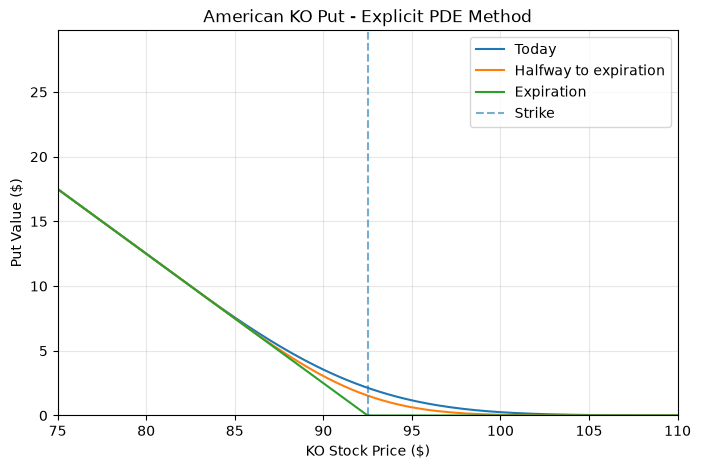

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(S_grid, V[:, 0], label="Today")
plt.plot(S_grid, V[:, NT // 2], label="Halfway to expiration")
plt.plot(S_grid, V[:, -1], label="Expiration")

plt.axvline(K, linestyle="--", alpha=0.6, label="Strike")

plt.xlabel("KO Stock Price ($)")
plt.ylabel("Put Value ($)")
plt.title("American KO Put - Explicit PDE Method")

plt.xlim(75, 110)
plt.ylim(bottom=0)

plt.grid(alpha=0.3)
plt.legend()

plt.show()

## 9. Comparison with the market price

The PDE price can be compared with the observed bid and ask prices of the option.

The model produces a value of approximately \$2.04, which lies inside the observed bid-ask spread of \$1.91 to \$2.12. It is also close to the market midpoint of \$2.015.

In [12]:
print(f"Bid:                 ${bid:.3f}")
print(f"Ask:                 ${ask:.3f}")
print(f"Market midpoint:     ${P_MKT:.3f}")
print(f"American PDE price:  ${P_PDE:.3f}")

relative_error = (P_PDE - P_MKT) / P_MKT * 100

print(f"Difference:          ${P_PDE - P_MKT:.3f}")
print(f"Difference (%):       {relative_error:.2f}%")

Bid:                 $1.910
Ask:                 $2.120
Market midpoint:     $2.015
American PDE price:  $2.042
Difference:          $0.027
Difference (%):       1.33%


## 10. Early exercise boundary

An American put can be exercised before expiration.

The exercise region consists of the stock prices for which the option value is equal to its intrinsic value. For each point in time, we find the highest stock price at which immediate exercise is optimal.

This gives the early exercise boundary.

In [13]:
# Find the early exercise boundary

exercise_boundary = np.full(NT + 1, np.nan)

tol = 1e-8

for n in range(NT + 1):

    exercise_region = (
        (intrinsic > 0)
        & (np.abs(V[:, n] - intrinsic) < tol)
    )

    if np.any(exercise_region):
        exercise_boundary[n] = S_grid[exercise_region].max()

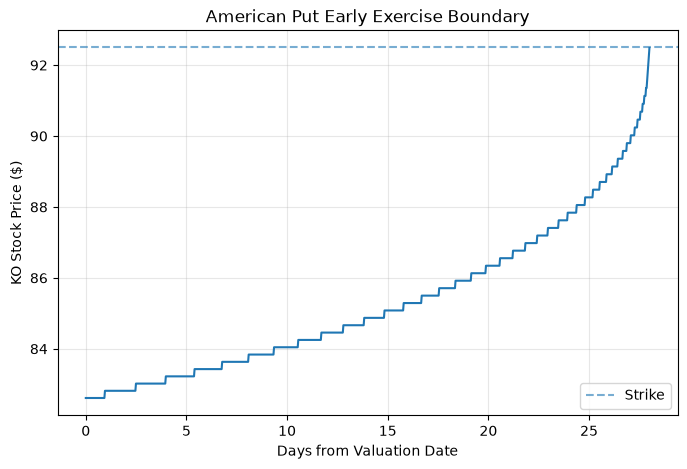

In [14]:
days = t_grid * 365

plt.figure(figsize=(8, 5))

plt.plot(days, exercise_boundary)
plt.axhline(K, linestyle="--", alpha=0.6, label="Strike")

plt.xlabel("Days from Valuation Date")
plt.ylabel("KO Stock Price ($)")
plt.title("American Put Early Exercise Boundary")

plt.grid(alpha=0.3)
plt.legend()

plt.show()

## Conclusion

Using current KO market data, the explicit finite difference method gives an American put value of approximately \$2.04.

The observed option has a bid of \$1.91 and an ask of \$2.12, with a midpoint of \$2.015. The PDE value therefore lies inside the observed bid-ask spread and is close to the market midpoint.

The American feature is incorporated by comparing the continuation value with the intrinsic value at every point in the grid. When the intrinsic value is larger, early exercise is optimal. This creates an exercise region for sufficiently low stock prices, with the exercise boundary approaching the strike as expiration gets closer.